# Making predictions with CoDiT

## Downloading relevant data

To predict with CoDiT models, we need to download the relevant context. The section below explains how this is done.
Before starting make sure you setup the config.ini with your credentials and the paths in `config_paths.py` are set correctly, such that you can access the climate data storage and copernicus marine.

If everything is setup it should be a matter of minutes to download modest context. 

Note, that the bigger you make this context the longer it will take to download. However, if you have a spatio-temporal region of interest, where you want to make predictions, it might make sense to extract a bigger context.

In [ ]:
%load_ext autoreload
%autoreload 2
import os
from datetime import datetime
from codit.data_module import config_paths, dataset_download, config_funcs
from matplotlib import pyplot as plt
from cartopy import crs
import cartopy.feature as cfeature
import logging


# Define the dataset configuration
# This is an example dataset configuration for a region in the Gulf of Mexico.
# Make sure that the 
name = "gulf_of_mexico"  # Name of the dataset
start_date = "2021-12-31"# Define the start and end dates for the dataset
end_date = "2022-01-06"  
coord_delta = 2.5        # Delta for latitude and longitude to define the area of interest
center_coord = [26, -90] # (lat, lon) around which to download the data


# Creates a config for the dataset
# This config will be used to download and later load the dataset.
# It will be also saved as readable config file.
min_lat, max_lat = center_coord[0] - coord_delta, center_coord[0] + coord_delta
min_lon, max_lon = center_coord[1] - coord_delta, center_coord[1] + coord_delta

dataset_path = os.path.join(config_paths.DATA_PATH, "datasets", "example_datasets")
config_path = os.path.join(config_paths.CONFIG_PATH, "example_datasets")
if not os.path.exists(os.path.join(config_paths.CONFIG_PATH, "example_datasets")):
    os.makedirs(os.path.join(config_paths.CONFIG_PATH, "example_datasets"))

start_time = datetime.strptime(start_date, "%Y-%m-%d")
end_time = datetime.strptime(end_date, "%Y-%m-%d")
data_config = {
            "name": f"example_dataset_{name}",
            "latitudes": [min_lat, max_lat],
            "longitudes": [min_lon, max_lon],
            "context_delta": coord_delta,
            "start_date": start_time,
            "end_date": end_time,
            "description": "",
            "dataset_path": os.path.join(dataset_path,),
        }

data_config = config_funcs.complete_config(data_config)
config_funcs.save_config(
    data_config,
    config_path,
    os.path.join(dataset_path, f"example_dataset_{name}"),
)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


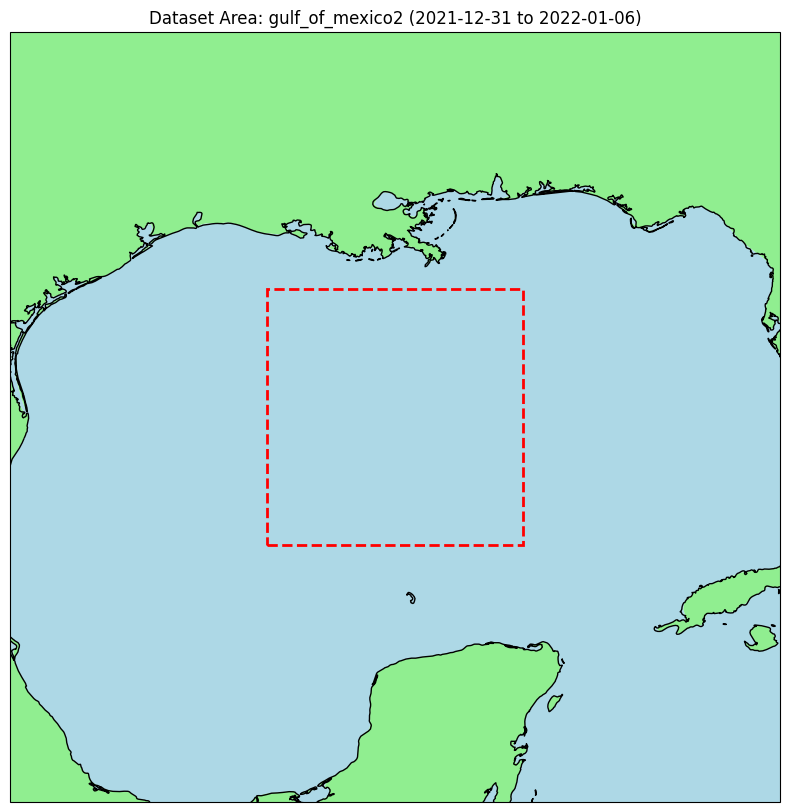

In [5]:
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(1, 1, 1, projection=crs.PlateCarree())
rect = plt.Rectangle(
    (min_lon, min_lat), max_lon - min_lon, max_lat - min_lat,
    facecolor='none', edgecolor='red', linewidth=2, linestyle='--'
)
ax.add_patch(rect)
#color water blue
ax.add_feature(cfeature.OCEAN, facecolor='lightblue')
ax.add_feature(cfeature.LAND, facecolor='lightgreen')
ax.set_extent([min_lon-5, max_lon+5, min_lat-5, max_lat+5],
              crs=crs.PlateCarree())
ax.coastlines(resolution='10m')
ax.set_title(f"Dataset Area: {name} ({start_date} to {end_date})")

plt.show()

In [6]:
dataset_download.download_drifter(data_config)
dataset_download.download_hycom(data_config)
dataset_download.download_era5(data_config)
dataset_download.download_copernicus(data_config)

Drifter data downloaded successfully


2025-09-15 07:41:46,632 INFO [2024-09-26T00:00:00] Watch our [Forum](https://forum.ecmwf.int/) for Announcements, news and other discussed topics.
INFO:ecmwf.datastores.legacy_client:[2024-09-26T00:00:00] Watch our [Forum](https://forum.ecmwf.int/) for Announcements, news and other discussed topics.


HYCOM data downloaded successfully


2025-09-15 07:41:46,879 INFO Request ID is 5f4dba27-7cd5-4323-b7cb-4ac4ac227f84
INFO:ecmwf.datastores.legacy_client:Request ID is 5f4dba27-7cd5-4323-b7cb-4ac4ac227f84
2025-09-15 07:41:46,977 INFO status has been updated to accepted
INFO:ecmwf.datastores.legacy_client:status has been updated to accepted
2025-09-15 07:41:56,011 INFO status has been updated to running
INFO:ecmwf.datastores.legacy_client:status has been updated to running
2025-09-15 08:06:09,068 INFO status has been updated to successful
INFO:ecmwf.datastores.legacy_client:status has been updated to successful


3e5b00d880266da16f25c81b43ecc7eb.grib:   0%|          | 0.00/116M [00:00<?, ?B/s]

ERA5 data downloaded successfully


INFO - 2025-09-15T08:06:39Z - Selected dataset version: "202311"
INFO:copernicusmarine:Selected dataset version: "202311"
INFO - 2025-09-15T08:06:39Z - Selected dataset part: "default"
INFO:copernicusmarine:Selected dataset part: "default"
INFO - 2025-09-15T08:06:40Z - Starting download. Please wait...
INFO:copernicusmarine:Starting download. Please wait...
INFO - 2025-09-15T08:06:41Z - Successfully downloaded to /tmp/copernicus_daily_timey2021m12d31_y2022m01d06_n28dot5_w-92dot5_s23dot5_e-87dot5.nc
INFO:copernicusmarine:Successfully downloaded to /tmp/copernicus_daily_timey2021m12d31_y2022m01d06_n28dot5_w-92dot5_s23dot5_e-87dot5.nc


Copernicus daily data downloaded successfully


### Load dataset

Since the data is downloaded we will create a dataset object that can be used by the machine learning models.

In [7]:
from codit.data_module.dataset import OceanDataset
prediction_length = 72  # hours
dataset = OceanDataset(data_config, length=prediction_length)

## Load model

Now we load a trained model. You can check for available models in the `trained_models` folder.

In general models for `open_ocean` are trained for 72h predictions, while coastline only for 24h. While the models can also make longer predictions, it one shouldn't expect meaning full results beyong these windows.

In [8]:
from codit.model_module import CoDiTModel, ConvNetModel, HycomModel
from jax import numpy as jnp

export_path = os.path.join(config_paths.DATA_PATH, 'trained_models/')
hycom_model = HycomModel('HYCOM_open_ocean', params={})
convnet_model = ConvNetModel.import_trained_model('cnn_open_ocean', import_path=export_path)
codit_gru_model = CoDiTModel.import_trained_model('codit_GRU_open_ocean', import_path=export_path)
codit_transformer_model = CoDiTModel.import_trained_model('codit_Transformer_open_ocean', import_path=export_path)
interpolator = dataset.get_interpolator(min_date=start_time, max_date=end_time)

Next we specify start position and time of the prediction, and how long we predict. Then we invoke the model prediction.

In [9]:
start_coord = jnp.asarray([26., -90.])  # lat, lon
start_time = datetime.strptime("2022-01-02-03:00", "%Y-%m-%d-%H:%M")
prediction_length = 72  # hours

In [10]:
predictions = {}
predictions['HYCOM'] = hycom_model.predict(
    start_coord,
    start_time,
    prediction_length=prediction_length,
    interpolator=interpolator,
    test_dataset=dataset,
)
logging.info("HYCOM prediction done")
predictions['CNN'] = convnet_model.predict(
    start_coord,
    start_time,
    prediction_length=prediction_length,
    interpolator=interpolator,
    test_dataset=dataset,
    num_samples=10,
)
logging.info("CNN prediction done")
predictions['CoDiT (GRU)'] = codit_gru_model.predict(
    start_coord,
    start_time,
    prediction_length=prediction_length,
    interpolator=interpolator,
    test_dataset=dataset,
    num_samples=10,
)
logging.info("CoDiT (GRU) prediction done")
predictions['CoDiT (Transformer)'] = codit_transformer_model.predict(
    start_coord,
    start_time,
    prediction_length=prediction_length,
    interpolator=interpolator,
    test_dataset=dataset,
    num_samples=10,
)
logging.info("CoDiT (Transformer) prediction done")

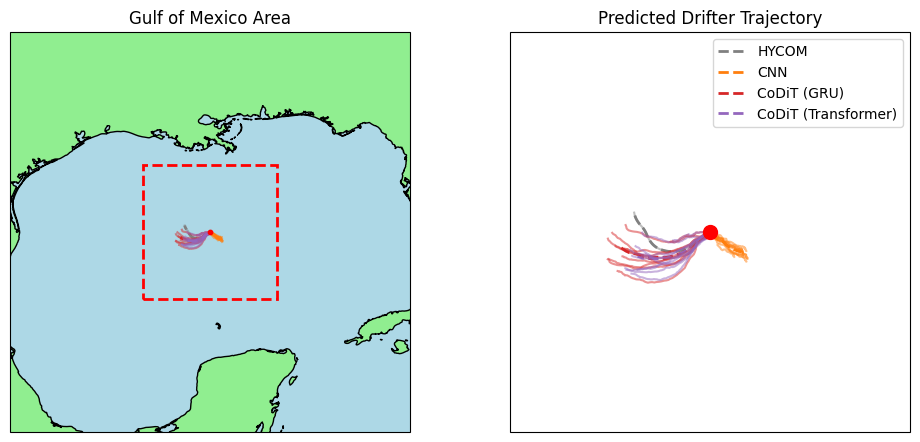

In [11]:
color_dict = {
    'HYCOM': 'grey',
    'CNN': 'C1',
    'CoDiT (GRU)': 'C3',
    'CoDiT (Transformer)': 'C4',
}
plt.figure(figsize=(10, 6))
ax1 = plt.axes((.05, 0, .4, 1), projection=crs.PlateCarree())
ax1.add_feature(cfeature.OCEAN, facecolor='lightblue')
ax1.add_feature(cfeature.LAND, facecolor='lightgreen')
ax1.set_extent([min_lon-5, max_lon+5, min_lat-5, max_lat+5],
              crs=crs.PlateCarree())
ax1.coastlines(resolution='10m')

for model_name, predicted_coords in predictions.items():
    ax1.plot(jnp.nanmean(predicted_coords[:, :, 1], axis=0), jnp.nanmean(predicted_coords[:, :, 0], axis=0), c=color_dict[model_name], label=model_name, linestyle='--', linewidth=2)
    ax1.plot(predicted_coords[:, :, 1].T, predicted_coords[:, :, 0].T, c=color_dict[model_name], label=model_name, alpha=0.5)
ax1.scatter(start_coord[1], start_coord[0], c='red', label='Start Coordinate', s=10, zorder=5)
ax1.add_patch(plt.Rectangle(
    (min_lon, min_lat), max_lon - min_lon, max_lat - min_lat,
    facecolor='none', edgecolor='red', linewidth=2, linestyle='--'
))

ax1.set_title('Gulf of Mexico Area')

ax2 = plt.axes((.55, 0, .4, 1), projection=crs.PlateCarree())
ax2.legend(loc='upper right')
for model_name, predicted_coords in predictions.items():
    ax2.plot(jnp.nanmean(predicted_coords[:, :, 1], axis=0), jnp.nanmean(predicted_coords[:, :, 0], axis=0), c=color_dict[model_name], label=model_name, linestyle='--', linewidth=2)
ax2.legend()

for model_name, predicted_coords in predictions.items():
    ax2.plot(predicted_coords[:, :, 1].T, predicted_coords[:, :, 0].T, c=color_dict[model_name], label=model_name, alpha=0.5)
ax2.scatter(start_coord[1], start_coord[0], c='red', label='Start Coordinate', s=100, zorder=5)
ax2.set_xlim((min_lon, max_lon))
ax2.set_ylim((min_lat, max_lat))
ax2.set_title('Predicted Drifter Trajectory')
plt.tight_layout()
plt.show()